In [10]:
import os
import numpy as np
import cv2 as cv
from skimage.io import imread
import matplotlib.pyplot as plt

# libraries to test
import sys
sys.path.append("../")
from frangi_2dfilter import frangi_2Dfilter
from fuzzy_thresholding import fuzzy_thresholding
from adaptive_thresholding import adaptive_thresholding

# Testing
We will be testing the Frangi 2D and Adaptive thresholding translations to ensure they work properly for skeletonization

# Utilities

In [11]:
def BinarizeImage(Im:np.ndarray, frangi_sigma = 8, frangi_enabled = True, method = "Fuzzy Means") -> np.ndarray:
    """
    Binarizes an image using the selected method and options from the GUI app.

    Parameters:
    - app: GUI application object containing UI state (e.g., checkboxes, dropdowns)
    - Im: Input image as a 2D NumPy array (grayscale)

    Returns:
    - Binarized image as a 2D NumPy array (dtype=float)
    """
    # Find the brightest pixel in the image
    col_max_vals = np.max(Im, axis=0) # the maximum of each column
    cc = np.argmax(col_max_vals) #  gets the index of the column where the brightest value occurred
    rr = np.argmax(Im[:, cc]) # captures the row index of that max value

    #	•	rr: row of the brightest pixel
	#   •	cc: column of the brightest pixel
    #   •	So (rr, cc) is the coordinate of the brightest pixel in the whole image.

    # Apply Frangi filter if selected
    if frangi_enabled:
        opts = {
            'sigmarange': [1, frangi_sigma],
            'sigmastepsize': 2,
            'correctionconst1': 0.8,
            'correctionconst2': 15
        }
        Im = frangi_2Dfilter(Im, opts)

    # Apply the selected binarization method
    if method == 'Fuzzy Means':
        nth = 2
        Im = fuzzy_thresholding(Im, nth, 3) - 1

    elif method == 'Adaptive Thresholding':
        Im = adaptive_thresholding(Im, 70).astype(float)

    else:
        raise ValueError("Incorrect Segmentation Method")

    # Ensure vessels are white, background is black, turning the image into black and white
    vessel_value = Im[rr, cc]
    Im[Im == vessel_value] = 255
    Im[Im != 255] = 0

    return Im

def overlay_mask(img, mask, color=(1, 0, 0), alpha=0.5):
    """
    Overlay a binary mask on a grayscale image.

    Parameters:
    - img: grayscale image (H,W)
    - mask: binary mask (H,W), values 0 or 255
    - color: tuple with RGB values (0-1 range for matplotlib)
    - alpha: transparency of overlay

    Returns:
    - RGB image with overlay
    """
    # Normalize grayscale for display
    img_norm = cv.normalize(img, None, 0, 1, cv.NORM_MINMAX)

    # Convert grayscale to RGB
    img_rgb = np.stack([img_norm]*3, axis=-1)

    # Create color mask
    mask_bool = mask > 0
    overlay = np.zeros_like(img_rgb)
    overlay[mask_bool] = color

    # Blend images
    blended = (1 - alpha) * img_rgb + alpha * overlay
    return blended


def center_crop(img, dim):
    """
    Center crop an image (2D NumPy array).

    Parameters:
        img (np.ndarray): Input image (H x W).
        dim (tuple): Desired output size (h, w).

    Returns:
        np.ndarray: Cropped image of size (h, w).
    """
    h, w = img.shape[:2]
    new_h, new_w = dim

    if new_h > h or new_w > w:
        raise ValueError("Crop size must be smaller than the image size")

    top = (h - new_h) // 2
    left = (w - new_w) // 2

    return img[top: top + new_h, left: left + new_w]

# Sample Image

In [12]:
octa_path = "../../assets/MIPs/10301.bmp"
img = imread(octa_path, as_gray=True)
img = img.astype(np.float32)

# Binarization
Frangi: built-in function from skimage

Thresholding: both fuzzy and adaptive are from the source code

In [13]:
import skfuzzy as fuzz
from skimage.filters import frangi

In [14]:
# frangi filtering first 
from matplotlib import colors

cmap_yellow = colors.ListedColormap(['black', 'yellow'])
vessels = frangi(
    img,
    scale_range=(0.5, 4),
    scale_step=0.5,
    alpha=0.5,
    beta=0.5,
    gamma=4,
    black_ridges=False
)

fuzzy_mask = BinarizeImage(vessels, 8, False)
adpt_mask = BinarizeImage(vessels, 8, False, method = "Adaptive Thresholding")

/tmp/ipykernel_47450/1139007971.py:5: UserWarning: Use keyword parameter `sigmas` instead of `scale_range` and `scale_range` which will be removed in version 0.17.
  vessels = frangi(


# Skeletonization
This implementation is using fully built-in python functions and other imported libraries. We are NOT translating the MATLAB code directly, simply replicating the data pipeline and workflow

In [20]:
import os
import glob
import math
from dataclasses import dataclass

import numpy as np
import matplotlib.pyplot as plt

from scipy.ndimage import distance_transform_edt, binary_dilation
from skimage.morphology import skeletonize  # 2D skeleton
# If you prefer a 3D-style skeleton op for 2D data, you can also use:
# from skimage.morphology import skeletonize_3d

# your provided functions
from Skel2Graph3D import skel2graph3d
from Graph2Skel3D import graph2skel3d


@dataclass
class Spinner:
    Value: float

# Minimal "app" example (you can use your own object with the same attributes)
@dataclass
class App:
    inputImage: np.ndarray            # 2D grayscale image
    TwigsizeSpinner: Spinner          # has a .Value attribute
    FileLabelName: str                # prefix for files
    bin_overlay: str = 'viridis'      # any Matplotlib colormap name
    imgSkel: np.ndarray = None        # will be set
    Gnodes: list = None               # will be set
    Glinks: list = None               # will be set


def _prune_by_min_branch_length_2d(skel_2d: np.ndarray, thr: float) -> np.ndarray:
    """
    Approximate MATLAB bwskel(..., 'MinBranchLength', thr) for a 2D skeleton
    by round-tripping through your graph representation and reconstructing
    without links shorter than `thr`.
    """
    if thr <= 0:
        return skel_2d.astype(bool)

    Nx, Ny = skel_2d.shape
    skel_3d = skel_2d.reshape(Nx, Ny, 1).astype(bool)

    # Use THR in skel2graph3d so short links are not created
    _, nodes, links = skel2graph3d(skel_3d, THR=thr)
    pruned = graph2skel3d(nodes, links, Nx, Ny, 1)
    return pruned[..., 0]  # back to 2D


def skeletonize_py(app, bin_img: np.ndarray, fol: str, disp: int):
    """
    Python translation of the MATLAB `skeletonize` function.
    Returns
        sk2 (2D bool array), TifFileName (str or None)
    """
    # --- enumerate existing outputs like MATLAB does
    existing = glob.glob(os.path.join(fol, "*_Skeleton*.tif"))
    imgnum = len(existing)

    # --- generate skeleton (MATLAB: bwmorph(L,'skel',Inf))
    L = bin_img.astype(bool)
    sk2 = skeletonize(L)  # (2D) – same effect as bwmorph 'skel' for binary images

    # --- prune short branches (MATLAB: bwskel(...,'MinBranchLength', Twig))
    twig = float(app.TwigsizeSpinner.Value)
    sk2 = _prune_by_min_branch_length_2d(sk2, twig)
    app.imgSkel = sk2.copy()

    Nx, Ny = app.inputImage.shape[:2]
    TifFileName = None

    # --- optional overlay saving (MATLAB display block)
    if disp == 1:
        # MATLAB bwmorph 'thicken' ≈ a light dilation to make lines visible
        sk2_vis = binary_dilation(sk2, structure=np.ones((3, 3), bool))

        base = app.inputImage.astype(float) * 3.0 / 4.0 + 10.0

        fig, ax = plt.subplots(figsize=(5, 5), dpi=100)
        ax.imshow(base, cmap=app.bin_overlay, origin='upper')
        # draw skeleton with alpha overlay; scale to 0..255 like MATLAB
        ax.imshow(sk2_vis.astype(float) * 255.0, cmap=app.bin_overlay, alpha=0.5, origin='upper')
        ax.set_axis_off()
        ax.set_aspect('equal')

        TifFileName = os.path.join(fol, f"{app.FileLabelName}_Skeleton_{imgnum}.tif")
        os.makedirs(os.path.dirname(TifFileName), exist_ok=True)
        fig.savefig(TifFileName, bbox_inches='tight', pad_inches=0)
        plt.close(fig)

    # --- Local thickness measurement (MATLAB: D = bwdist(~L) * 2)
    # distance_transform_edt returns Euclidean distance to nearest False
    D = distance_transform_edt(~L) * 2.0

    if disp == 1:
        pngFileName = os.path.join(fol, f"{app.FileLabelName}_Local thickness_{imgnum}.png")
        D_norm = D / (np.max(D) if np.max(D) > 0 else 1.0)
        plt.imsave(pngFileName, (D_norm * 255.0).astype(np.uint8), cmap='hot')

    # --- Network analysis (Skel2Graph3D / Graph2Skel3D cleanup loop)
    if np.sum(app.imgSkel) == 0:
        nodes, links = [], []
    else:
        skel3d = app.imgSkel.reshape(Nx, Ny, 1).astype(bool)

        # initial graph with threshold to prune tiny links
        _, nodes, links = skel2graph3d(skel3d, THR=twig)

        # total length proxy = sum of number of incident links per node (to mirror MATLAB)
        def total_incident_links(ns):  # same as sum(cellfun('length',{nodes.links}))
            return sum(len(n['links']) for n in ns)

        wl = total_incident_links(nodes)

        # reconstruct & re-extract graph with THR=0, repeat until stable
        while True:
            skel2_clean = graph2skel3d(nodes, links, Nx, Ny, 1)
            _, nodes_new, links_new = skel2graph3d(skel2_clean, THR=0)
            wl_new = total_incident_links(nodes_new)

            if wl_new == wl:
                nodes, links = nodes_new, links_new
                break

            nodes, links = nodes_new, links_new
            wl = wl_new

    app.Gnodes = nodes
    app.Glinks = links

    # --- Augment link metrics (coordinates, lengths, tortuosity, diameters)
    for lk in app.Glinks:
        pts = np.array(lk['point'], dtype=int)
        # unravel in (Nx, Ny, 1) indexing
        x, y, z = np.unravel_index(pts, (Nx, Ny, 1))
        x, y = x.astype(float), y.astype(float)

        lk['x'] = x.tolist()
        lk['y'] = y.tolist()

        # pixel-path length
        if len(x) >= 2:
            diffs = np.diff(np.stack([y, x], axis=1), axis=0)  # (n-1, 2)
            pix_len = float(np.sum(np.sqrt(np.sum(diffs * diffs, axis=1))))
        else:
            pix_len = 0.0

        # end-to-end length
        if len(x) >= 1:
            e2e = float(math.hypot(x[-1] - x[0], y[-1] - y[0]))
        else:
            e2e = 0.0

        lk['pixLength'] = pix_len
        lk['end2endLength'] = e2e
        lk['tortuosity'] = (pix_len / e2e) if e2e > 0 else np.inf

        # diameters from local thickness map
        lk['diameterMeasurements'] = D.flat[pts].astype(float).tolist()
        lk['diameter'] = float(np.mean(D.flat[pts])) if len(pts) > 0 else 0.0

    # --- Optional graph overlay (like MATLAB final display)
    if disp == 1 and len(nodes) > 0:
        fig, ax = plt.subplots(figsize=(5, 5), dpi=100)
        ax.imshow(app.inputImage, cmap='gray', origin='upper')
        ax.set_axis_off()
        ax.set_aspect('equal')

        # draw links with color rules similar to MATLAB
        for i, nd in enumerate(nodes):
            x1, y1 = nd['comx'], nd['comy']

            for j, li in enumerate(nd['links']):
                if li < 0:
                    continue
                other = nodes[nd['conn'][j]]
                # color logic approximating MATLAB
                if other['ep'] == 1 and nd['ep'] == 1:
                    col = 'b'
                elif other['ep'] == 1 or nd['ep'] == 1:
                    col = 'g'
                else:
                    col = 'y'

                yy = app.Glinks[li]['y']
                xx = app.Glinks[li]['x']
                ax.plot(yy, xx, color=col, linewidth=2)

            # draw nodes (non-endpoints) as small circles
            if nd['ep'] == 0:
                ax.plot([y1], [x1], 'o', markersize=4, markerfacecolor='m', color='k')

        overlay_name = os.path.join(fol, f"{app.FileLabelName}_Overlay_{imgnum}.tif")
        fig.savefig(overlay_name, bbox_inches='tight', pad_inches=0)
        plt.close(fig)

    return app.imgSkel.astype(bool), TifFileName

In [ ]:
adpt_mask_cropped = center_crop(adpt_mask, (100, 100))
test3 = skeletonize_py(img, adpt_mask, 5)

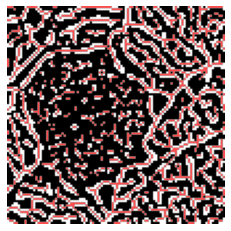

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.morphology import skeletonize
from skimage import data, color

# -------------------
# Fake "app" object
# -------------------
class App:
    def __init__(self, inputImage, bin_img):
        self.inputImage = inputImage
        self.bin_img = bin_img

# use a sample image (coins) from skimage
img = adpt_mask_cropped
app = App(img, adpt_mask_cropped)

# skeletonize
skel = skeletonize(app.bin_img)

# -------------------
# Show overlay
# -------------------
fig, ax = plt.subplots()
ax.imshow(app.inputImage, cmap="gray")  # original
ax.imshow(np.ma.masked_where(skel == 0, skel), cmap="autumn", alpha=0.7)  # skeleton
ax.axis("off")
plt.show()


Text(0.5, 1.0, 'Skeletonization (built-in + algo)')

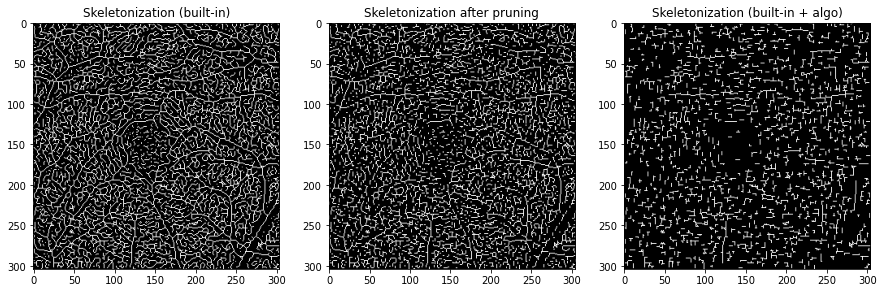

In [12]:
fig, ax = plt.subplots(1, 3, figsize = (15, 15))

ax[0].imshow(test, cmap = 'gray')
ax[0].set_title("Skeletonization (built-in)")

ax[1].imshow(test2, cmap = 'gray')
ax[1].set_title("Skeletonization after pruning")

ax[2].imshow(test3[0], cmap = 'gray')
ax[2].set_title("Skeletonization (built-in + algo)")